# Part 1: The Classical SIR Model

## Building Our First Epidemic Model from First Principles

---

## Goal

In this notebook, we will:
1. Define the state variables of an epidemic
2. Derive the SIR differential equations step-by-step
3. Understand the parameters β (beta) and γ (gamma)
4. Introduce the basic reproduction number R₀
5. Simulate and visualize epidemic dynamics
6. Explore how parameters affect outcomes

In [1]:
# Add src to path
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Import our SIR module
from sir import sir_rhs, simulate_sir, plot_sir
from utils import compute_R0, find_peak
from visualisation import plot_phase_portrait, plot_heatmap

# Set random seed
np.random.seed(42)

print("✓ Setup complete")

✓ Setup complete


## 1.1 State Variables

The SIR model partitions the population into three **compartments**:

### S(t) — Susceptible
Individuals who **can** catch the disease.

### I(t) — Infected
Individuals who **have** the disease and can spread it to others.

### R(t) — Recovered
Individuals who **had** the disease and are now immune.

---

### Conservation Law

The total population N remains constant:

$$N = S(t) + I(t) + R(t)$$

This means we're assuming:
- No births or deaths
- No immigration or emigration
- The disease doesn't kill anyone

These assumptions make the model **simpler** but also **less realistic**. We'll relax them later.

## 1.2 How Infection Happens

For a new infection to occur, we need:
1. A **susceptible** individual (S)
2. An **infected** individual (I)
3. **Contact** between them

### Building Intuition

- If there are **more infected** people (I is large), infection spreads faster
- If there are **more susceptible** people (S is large), there are more targets
- If there are **more contacts**, transmission is more likely

### The Key Assumption: Homogeneous Mixing

The SIR model assumes **everyone meets everyone equally**. This is called **homogeneous mixing** or **mass action**.

Under this assumption, the infection rate is proportional to the product:

$$\text{Infection rate} \propto S \cdot I$$

We introduce a constant β (beta) to set the scale:

$$\text{New infections per unit time} = \beta \frac{S \cdot I}{N}$$

The division by N normalizes for population size.

## 1.3 Recovery Mechanism

Infected individuals recover at some rate. The simplest assumption is:

### Each infected person recovers independently

If the **average infectious period** is 1/γ days, then:
- γ (gamma) is the **recovery rate**
- A fraction γ of infected individuals recover each day

$$\text{Recoveries per unit time} = \gamma \cdot I$$

### Example
- If γ = 0.1 per day, then the average infectious period is 1/0.1 = 10 days
- If γ = 0.2 per day, then the average infectious period is 1/0.2 = 5 days

## 1.4 Deriving the SIR Equations

Now we put everything together.

### Rate of change of S
Susceptible individuals **decrease** when they get infected:

$$\frac{dS}{dt} = -\beta \frac{S \cdot I}{N}$$

### Rate of change of I
Infected individuals **increase** from new infections and **decrease** from recoveries:

$$\frac{dI}{dt} = \beta \frac{S \cdot I}{N} - \gamma I$$

### Rate of change of R
Recovered individuals **increase** from recoveries:

$$\frac{dR}{dt} = \gamma I$$

---

### Check: Conservation
Adding all three equations:

$$\frac{dS}{dt} + \frac{dI}{dt} + \frac{dR}{dt} = -\beta \frac{SI}{N} + \beta \frac{SI}{N} - \gamma I + \gamma I = 0$$

✓ The total population remains constant!

## 1.5 Understanding the Parameters

### β (beta) — Transmission Rate
- **Higher β** → disease spreads faster
- Depends on:
  - Contact rate (how often people meet)
  - Transmission probability per contact

### γ (gamma) — Recovery Rate
- **Higher γ** → people recover faster → shorter infectious period
- Infectious period = 1/γ

### The Ratio β/γ
The ratio β/γ determines whether an epidemic will grow or die out.

## 1.6 The Basic Reproduction Number R₀

### Definition
**R₀** (pronounced "R-naught") is the **expected number of secondary infections** caused by one infected individual in a **completely susceptible** population.

For the SIR model:

$$R_0 = \frac{\beta}{\gamma}$$

### Physical Interpretation
- **R₀ > 1**: Each infected person infects more than one other → **epidemic grows**
- **R₀ = 1**: Each infected person infects exactly one other → **endemic steady state**
- **R₀ < 1**: Each infected person infects less than one other → **epidemic dies out**

### Why β/γ?
- An infected person is infectious for an average time of **1/γ**
- During this time, they make contacts at rate **β**
- In a fully susceptible population, all contacts lead to infection
- Total infections = β × (1/γ) = **β/γ** = **R₀**

## 1.7 Our First Simulation

Let's simulate an epidemic with:
- N = 1000 people
- S(0) = 990 (99% susceptible)
- I(0) = 10 (1% infected)
- R(0) = 0 (no one recovered yet)
- β = 0.5 per day
- γ = 0.1 per day
- R₀ = 0.5 / 0.1 = 5.0

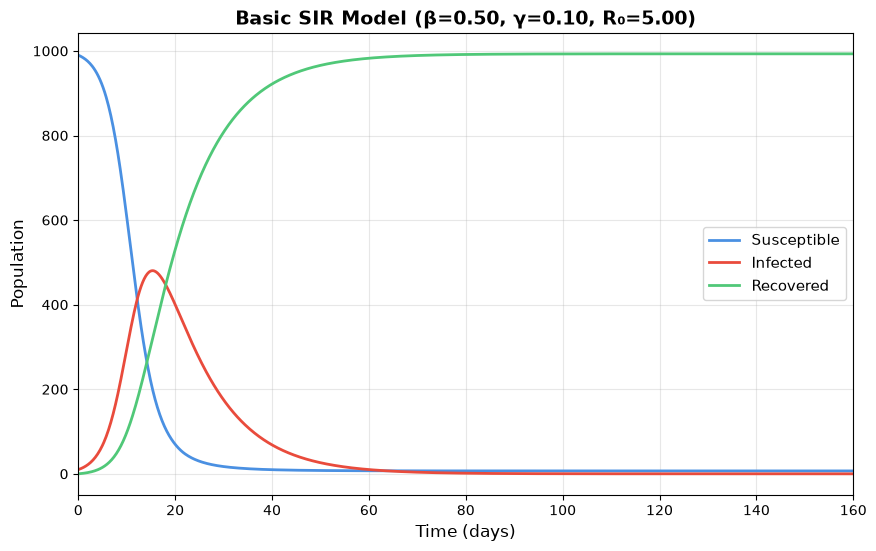

Epidemic Peak:
  Time: 15.4 days
  Infected: 480 people (48.0%)
  R₀ = 5.00


In [2]:
# Parameters
beta = 0.5
gamma = 0.1
N = 1000

# Initial conditions
S0 = 990
I0 = 10
R0 = 0

# Simulate
solution = simulate_sir(beta, gamma, S0, I0, R0, t_span=(0, 160))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
plot_sir(solution, beta=beta, gamma=gamma, title="Basic SIR Model", ax=ax)
plt.show()

# Find peak
t = solution.t
S, I, R = solution.y
peak_time, peak_value, _ = find_peak(t, I)

print(f"Epidemic Peak:")
print(f"  Time: {peak_time:.1f} days")
print(f"  Infected: {peak_value:.0f} people ({100*peak_value/N:.1f}%)")
print(f"  R₀ = {compute_R0(beta, gamma):.2f}")

**Figure 1**: Basic SIR epidemic curve showing susceptible (blue), infected (red), and recovered (green) populations over time.

### Observations

1. **The epidemic grows exponentially** at first when S ≈ N
2. **Infections peak** and then decline
3. **Not everyone gets infected** — some people remain susceptible
4. **The susceptible population never reaches zero** — the epidemic ends when there aren't enough susceptible people left, not when they run out

## Figure 2: Infection Peak Annotation

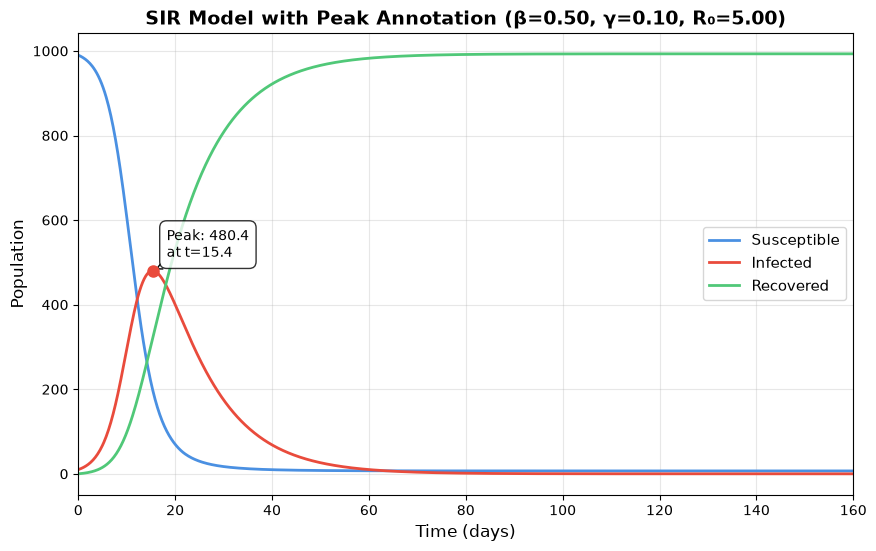

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_sir(solution, beta=beta, gamma=gamma, title="SIR Model with Peak Annotation", 
         show_peak=True, ax=ax)
plt.show()

## Figure 3: Phase Portrait (S vs I)

A phase portrait shows the relationship between two variables without time.

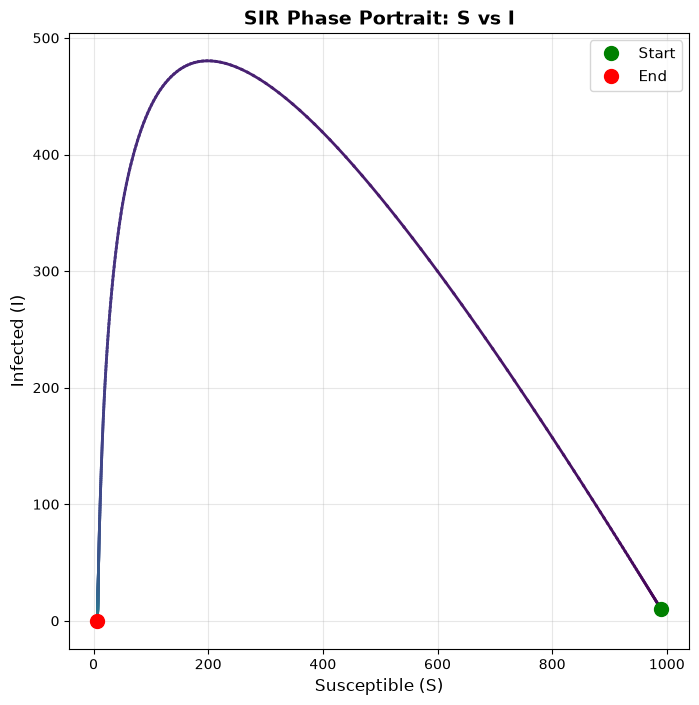

The trajectory shows how the system evolves from green (start) to red (end).
Notice: infections increase while S is high, then decrease as S depletes.


In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
plot_phase_portrait(S, I, title="SIR Phase Portrait: S vs I", ax=ax, show_trajectory=True)
plt.show()

print("The trajectory shows how the system evolves from green (start) to red (end).")
print("Notice: infections increase while S is high, then decrease as S depletes.")

## Exploring Parameters

How do β and γ affect the epidemic?

## Figure 4: Varying β (Transmission Rate)

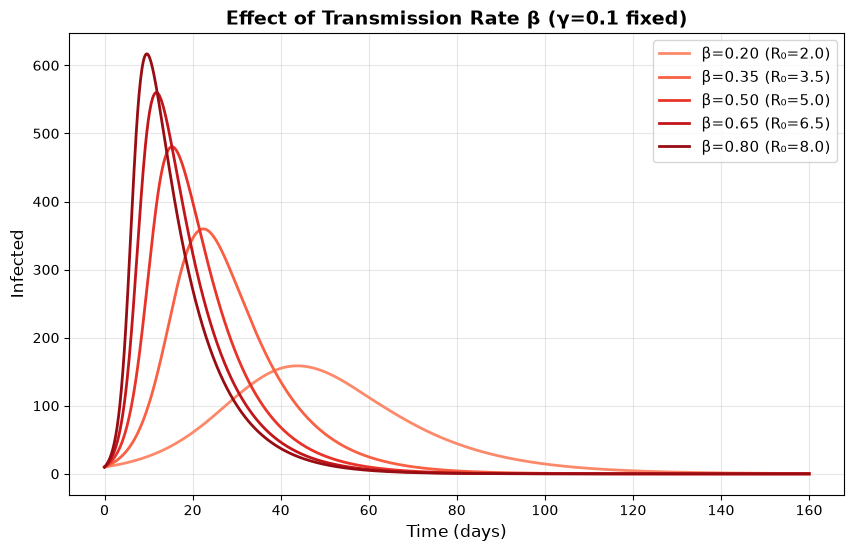

Higher β → faster spread, higher peak, earlier peak


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

gamma_fixed = 0.1
beta_values = [0.2, 0.35, 0.5, 0.65, 0.8]
colors = plt.cm.Reds(np.linspace(0.4, 0.9, len(beta_values)))

for i, beta_val in enumerate(beta_values):
    sol = simulate_sir(beta_val, gamma_fixed, S0, I0, R0, t_span=(0, 160))
    t = sol.t
    I_vals = sol.y[1]
    R0_val = compute_R0(beta_val, gamma_fixed)
    ax.plot(t, I_vals, label=f'β={beta_val:.2f} (R₀={R0_val:.1f})', 
            linewidth=2, color=colors[i])

ax.set_xlabel('Time (days)', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Effect of Transmission Rate β (γ=0.1 fixed)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.show()

print("Higher β → faster spread, higher peak, earlier peak")

## Figure 5: Varying γ (Recovery Rate)

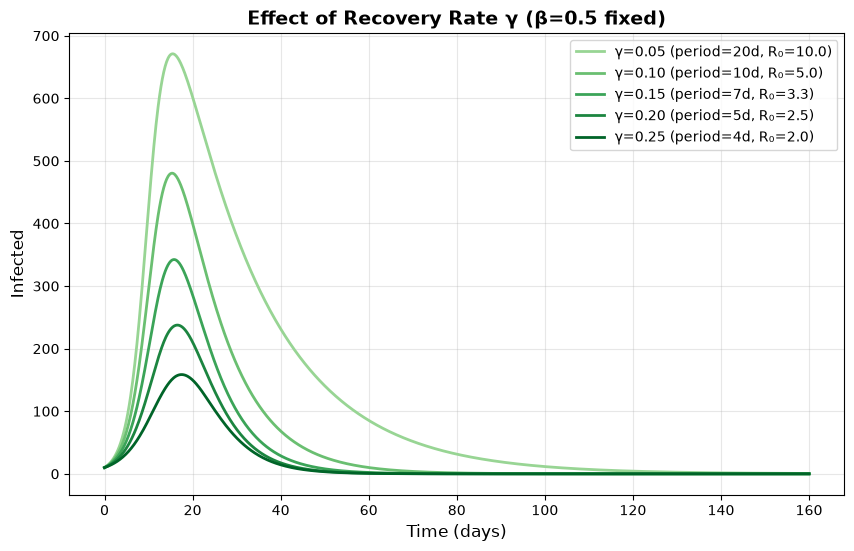

Higher γ → shorter infectious period → lower R₀ → smaller epidemic


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

beta_fixed = 0.5
gamma_values = [0.05, 0.1, 0.15, 0.2, 0.25]
colors = plt.cm.Greens(np.linspace(0.4, 0.9, len(gamma_values)))

for i, gamma_val in enumerate(gamma_values):
    sol = simulate_sir(beta_fixed, gamma_val, S0, I0, R0, t_span=(0, 160))
    t = sol.t
    I_vals = sol.y[1]
    R0_val = compute_R0(beta_fixed, gamma_val)
    infectious_period = 1/gamma_val
    ax.plot(t, I_vals, 
            label=f'γ={gamma_val:.2f} (period={infectious_period:.0f}d, R₀={R0_val:.1f})', 
            linewidth=2, color=colors[i])

ax.set_xlabel('Time (days)', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Effect of Recovery Rate γ (β=0.5 fixed)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.show()

print("Higher γ → shorter infectious period → lower R₀ → smaller epidemic")

## Figure 6: Heatmap of Peak Infection vs β and γ

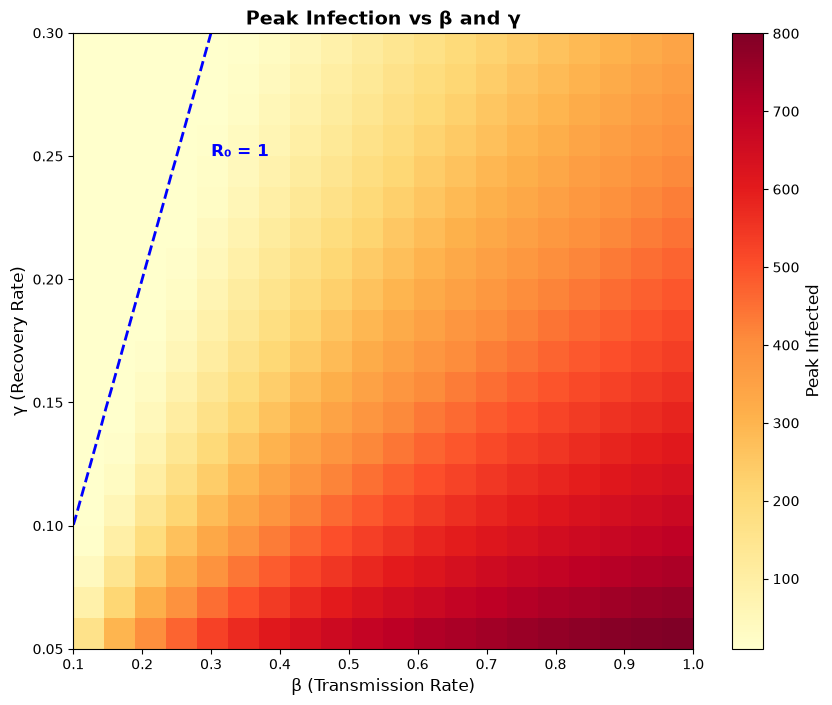

The blue dashed line shows R₀ = 1, the epidemic threshold.
Above the line: epidemic occurs. Below: epidemic dies out.


In [7]:
# Parameter ranges
beta_range = np.linspace(0.1, 1.0, 20)
gamma_range = np.linspace(0.05, 0.3, 20)

# Compute peak infections
peak_matrix = np.zeros((len(gamma_range), len(beta_range)))

for i, gamma_val in enumerate(gamma_range):
    for j, beta_val in enumerate(beta_range):
        sol = simulate_sir(beta_val, gamma_val, S0, I0, R0, t_span=(0, 160))
        I_vals = sol.y[1]
        peak_matrix[i, j] = I_vals.max()

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(peak_matrix, aspect='auto', origin='lower',
               extent=[beta_range[0], beta_range[-1], gamma_range[0], gamma_range[-1]],
               cmap='YlOrRd')

# Add R0 = 1 contour
B, G = np.meshgrid(beta_range, gamma_range)
R0_vals = B / G
ax.contour(B, G, R0_vals, levels=[1], colors='blue', linewidths=2, linestyles='--')
ax.text(0.3, 0.25, 'R₀ = 1', color='blue', fontsize=12, fontweight='bold')

ax.set_xlabel('β (Transmission Rate)', fontsize=12)
ax.set_ylabel('γ (Recovery Rate)', fontsize=12)
ax.set_title('Peak Infection vs β and γ', fontsize=14, fontweight='bold')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Peak Infected', fontsize=12)

plt.show()

print("The blue dashed line shows R₀ = 1, the epidemic threshold.")
print("Above the line: epidemic occurs. Below: epidemic dies out.")

## Summary: What We've Learned

### The SIR Model
- Partitions population into **S**, **I**, **R** compartments
- Uses **ordinary differential equations** to describe dynamics
- Assumes **homogeneous mixing** (everyone meets everyone)

### Key Parameters
- **β**: transmission rate (contacts × probability)
- **γ**: recovery rate (= 1 / infectious period)
- **R₀ = β/γ**: basic reproduction number

### Key Insights
1. Epidemics grow exponentially initially
2. They peak and decline **before** susceptibles run out
3. **R₀ > 1** is required for an epidemic
4. Higher β → faster, larger epidemic
5. Higher γ → slower, smaller epidemic

---

## Limitations

But the SIR model has limitations:
1. **No latency period** — people become infectious immediately after infection
2. **Homogeneous mixing** — unrealistic for real populations
3. **No spatial structure**
4. **No demographics** (births, deaths, aging)

**Next**: We'll address the latency problem by introducing the **SEIR model**.